# Name: Dhananjay Gandhi
# Section: B2
# SI Lab – Project

# Internship Stipend Prediction Using Web Scraping and Machine Learning

**Aim:** Collect publicly visible internship/job listing information from a website, clean and explore the data, apply statistical inference techniques, and compare five regression models to predict the monthly stipend.

**Website selected:** Wellfound (public job listings). Public listings sometimes display compensation ranges and internship roles, making it a more suitable starting point than websites whose terms explicitly prohibit automated collection for machine-learning purposes. Before running the scraper, review the current website terms and `robots.txt`; only collect public pages, use a low request rate, and stop if access is denied. Do not bypass login, CAPTCHA, or access controls.

**Important limitation:** The number of listings that expose a numeric stipend can vary. The notebook will report how many records were collected and how many have usable compensation. Do not treat missing compensation as zero.

## Step 0: Install and Import Required Libraries

In [ ]:
!pip -q install beautifulsoup4 lxml requests pandas numpy matplotlib seaborn scipy scikit-learn

In [ ]:
import re
import time
import json
import warnings
from urllib.parse import urljoin, urlparse
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme()

## Web Scraping: Collect Internship Listing Data

The scraper below tries to collect public Wellfound job-detail links from a search/listing page, then reads each public listing page. Website layouts change, so selectors may need updating. It does not log in or bypass access restrictions.

If the website blocks automated requests or returns too few listings, stop rather than attempting to bypass the restriction. You can instead use a manually downloaded/exported dataset where permitted, or enter publicly accessible listing URLs you are allowed to process.

In [ ]:
BASE_URL = "https://wellfound.com"
SEARCH_URL = "https://wellfound.com/jobs"

HEADERS = {
    "User-Agent": "Mozilla/5.0 (compatible; StudentResearchProject/1.0)"
}

def get_soup(url):
    response = requests.get(url, headers=HEADERS, timeout=20)
    response.raise_for_status()
    return BeautifulSoup(response.text, "lxml")

def find_job_links(search_url, max_links=80):
    soup = get_soup(search_url)
    links = []
    for a in soup.select('a[href*="/jobs/"]'):
        href = a.get("href", "")
        full_url = urljoin(BASE_URL, href)
        if "/jobs/" in urlparse(full_url).path and full_url not in links:
            links.append(full_url.split("?")[0])
        if len(links) >= max_links:
            break
    return links

try:
    job_urls = find_job_links(SEARCH_URL, max_links=80)
    print("Public job links found:", len(job_urls))
    print(job_urls[:10])
except Exception as e:
    job_urls = []
    print("Automatic listing discovery was unsuccessful:", e)
    print("Check the website manually and add permitted public listing URLs to MANUAL_JOB_URLS below.")

Public job links found: 51
['https://wellfound.com/jobs/signup', 'https://wellfound.com/jobs/4897407-data-curator-chicago', 'https://wellfound.com/jobs/4897405-managing-video-editor', 'https://wellfound.com/jobs/4810221-ai-engineer-ny', 'https://wellfound.com/jobs/4362956-office-administrator', 'https://wellfound.com/jobs/4288755-director-of-revenue-operations', 'https://wellfound.com/jobs/4427735-senior-engineer', 'https://wellfound.com/jobs/4895915-senior-software-engineer-ai-agents', 'https://wellfound.com/jobs/4895904-software-engineer-financial-systems', 'https://wellfound.com/jobs/4895885-full-stack-engineer-enterprise']


In [ ]:
MANUAL_JOB_URLS = [
    # Add public Wellfound internship/job detail URLs here if listing discovery returns too few links.
]

job_urls = list(dict.fromkeys(job_urls + MANUAL_JOB_URLS))
print("Total unique listing URLs to process:", len(job_urls))

Total unique listing URLs to process: 51


### Extract fields from each listing

In [ ]:
def extract_compensation(text):
    text = re.sub(r"\s+", " ", text)
    patterns = [
        r"(?:₹|INR\s*)\s?([\d,]+)\s*(?:-|–|to)\s*(?:₹|INR\s*)?([\d,]+)\s*(?:/\s*month|per month|monthly|\/mo)?",
        r"(?:₹|INR\s*)\s?([\d,]+)\s*(?:\/\s*month|per month|monthly|\/mo)",
        r"\$\s?([\d,]+)\s*(?:-|–|to)\s*\$?\s?([\d,]+)\s*(?:\/\s*month|per month|monthly|\/mo)?"
    ]
    for p in patterns:
        m = re.search(p, text, flags=re.I)
        if m:
            nums = [float(x.replace(",", "")) for x in m.groups() if x]
            if len(nums) >= 2:
                return float(np.mean(nums)), "range"
            if len(nums) == 1:
                return nums[0], "single"
    return np.nan, "not found"

def extract_listing(url):
    soup = get_soup(url)
    for tag in soup(["script", "style", "noscript", "svg"]):
        tag.decompose()
    text = soup.get_text(" ", strip=True)
    title = soup.title.get_text(" ", strip=True) if soup.title else ""
    h1 = soup.find("h1")
    if h1:
        title = h1.get_text(" ", strip=True)
    company = ""
    for selector in ['[data-test="StartupName"]', '[class*="company"]', '[class*="Company"]']:
        node = soup.select_one(selector)
        if node:
            company = node.get_text(" ", strip=True)
            if company:
                break
    stipend, compensation_type = extract_compensation(text)
    location = ""
    for selector in ['[class*="location"]', '[data-test*="location"]']:
        node = soup.select_one(selector)
        if node:
            location = node.get_text(" ", strip=True)
            if location:
                break
    return {
        "title": title[:250],
        "company": company[:150],
        "location": location[:150],
        "stipend_monthly_raw": stipend,
        "compensation_match_type": compensation_type,
        "description_text": text[:12000],
        "url": url
    }

records = []
for i, url in enumerate(job_urls, start=1):
    try:
        records.append(extract_listing(url))
        print(f"Collected {i}/{len(job_urls)}")
    except Exception as e:
        print(f"Skipped listing {i}: {e}")
    time.sleep(2)

raw_df = pd.DataFrame(records)
print("Scraped records:", len(raw_df))
raw_df.head()

Collected 1/51
Collected 2/51
Collected 3/51
Collected 4/51
Collected 5/51
Collected 6/51
Collected 7/51
Collected 8/51
Collected 9/51
Collected 10/51
Collected 11/51
Collected 12/51
Collected 13/51
Collected 14/51
Collected 15/51
Collected 16/51
Collected 17/51
Collected 18/51
Collected 19/51
Collected 20/51
Collected 21/51
Collected 22/51
Collected 23/51
Collected 24/51
Collected 25/51
Collected 26/51
Collected 27/51
Collected 28/51
Collected 29/51
Collected 30/51
Collected 31/51
Collected 32/51
Collected 33/51
Collected 34/51
Collected 35/51
Collected 36/51
Collected 37/51
Collected 38/51
Collected 39/51
Collected 40/51
Collected 41/51
Collected 42/51
Collected 43/51
Collected 44/51
Collected 45/51
Collected 46/51
Collected 47/51
Collected 48/51
Collected 49/51
Collected 50/51
Collected 51/51
Scraped records: 51


,title,company,location,stipend_monthly_raw,compensation_match_type,description_text,url
0,Find what's next,,,NaN,not found,Sign Up | Wellfound Log in Find what's next Cr...,https://wellfound.com/jobs/signup
1,Data Curator (Chicago),,,NaN,not found,Data Curator (Chicago) at Blinkfire Analytics ...,https://wellfound.com/jobs/4897407-data-curato...
2,Managing Video Editor,,,NaN,not found,Managing Video Editor at Sift Clips • Orlando ...,https://wellfound.com/jobs/4897405-managing-vi...
3,AI Engineer - NY,,,175000.0,range,AI Engineer - NY at Scope Labs • New York City...,https://wellfound.com/jobs/4810221-ai-engineer-ny
4,Office Administrator,,,NaN,not found,Office Administrator at Arxlight • Oakland | W...,https://wellfound.com/jobs/4362956-office-admi...


### Normalize compensation and save the raw scraped data

In [ ]:
if raw_df.empty:
    raw_df = pd.DataFrame(columns=[
        "title", "company", "location", "stipend_monthly_raw",
        "compensation_match_type", "description_text", "url"
    ])

def infer_monthly_amount(row):
    value = row.get("stipend_monthly_raw", np.nan)
    if pd.isna(value):
        return np.nan
    text = str(row.get("description_text", "")).lower()
    # Do not convert annual salaries to monthly unless an annual unit is explicit.
    if any(term in text for term in ["per year", "annual", "yearly", "/year", "lpa", "per annum"]):
        if any(term in text for term in ["monthly", "per month", "/month", "stipend"]):
            return float(value)
        return np.nan
    return float(value)

raw_df["stipend_monthly"] = raw_df.apply(infer_monthly_amount, axis=1)
raw_df.to_csv("wellfound_internship_scraped_raw.csv", index=False)
print("Saved wellfound_internship_scraped_raw.csv")
raw_df[["title", "company", "location", "stipend_monthly", "url"]].head(10)

Saved wellfound_internship_scraped_raw.csv


,title,company,location,stipend_monthly,url
0,Find what's next,,,NaN,https://wellfound.com/jobs/signup
1,Data Curator (Chicago),,,NaN,https://wellfound.com/jobs/4897407-data-curato...
2,Managing Video Editor,,,NaN,https://wellfound.com/jobs/4897405-managing-vi...
3,AI Engineer - NY,,,175000.0,https://wellfound.com/jobs/4810221-ai-engineer-ny
4,Office Administrator,,,NaN,https://wellfound.com/jobs/4362956-office-admi...
5,Director of Revenue Operations,,,NaN,https://wellfound.com/jobs/4288755-director-of...
6,Senior Engineer,,,190000.0,https://wellfound.com/jobs/4427735-senior-engi...
7,Senior Software Engineer (AI Agents),,,NaN,https://wellfound.com/jobs/4895915-senior-soft...
8,"Software Engineer, Financial Systems",,,125000.0,https://wellfound.com/jobs/4895904-software-en...
9,Full-Stack Engineer - Enterprise,,,NaN,https://wellfound.com/jobs/4895885-full-stack-...


## Practical 3 – Part A: Import, Clean and Describe the Data

The prediction target is `stipend_monthly`. Some job pages publish annual salary, equity, or no compensation; those values must not be silently treated as monthly stipends. The simple extractor is only a starting point and should be manually checked against listing pages.

### Task A1: Inspect the collected dataset

In [ ]:
df = raw_df.copy()
print("Shape:", df.shape)
display(df.head(10))

Shape: (51, 8)


,title,company,location,stipend_monthly_raw,compensation_match_type,description_text,url,stipend_monthly
0,Find what's next,,,NaN,not found,Sign Up | Wellfound Log in Find what's next Cr...,https://wellfound.com/jobs/signup,NaN
1,Data Curator (Chicago),,,NaN,not found,Data Curator (Chicago) at Blinkfire Analytics ...,https://wellfound.com/jobs/4897407-data-curato...,NaN
2,Managing Video Editor,,,NaN,not found,Managing Video Editor at Sift Clips • Orlando ...,https://wellfound.com/jobs/4897405-managing-vi...,NaN
3,AI Engineer - NY,,,175000.0,range,AI Engineer - NY at Scope Labs • New York City...,https://wellfound.com/jobs/4810221-ai-engineer-ny,175000.0
4,Office Administrator,,,NaN,not found,Office Administrator at Arxlight • Oakland | W...,https://wellfound.com/jobs/4362956-office-admi...,NaN
5,Director of Revenue Operations,,,225000.0,range,Director of Revenue Operations at Kontakt.io •...,https://wellfound.com/jobs/4288755-director-of...,NaN
6,Senior Engineer,,,190000.0,range,Senior Engineer at GoodParty.org • United Sta...,https://wellfound.com/jobs/4427735-senior-engi...,190000.0
7,Senior Software Engineer (AI Agents),,,NaN,not found,Senior Software Engineer (AI Agents) at Traba ...,https://wellfound.com/jobs/4895915-senior-soft...,NaN
8,"Software Engineer, Financial Systems",,,125000.0,range,"Software Engineer, Financial Systems at Madhiv...",https://wellfound.com/jobs/4895904-software-en...,125000.0
9,Full-Stack Engineer - Enterprise,,,NaN,not found,Full-Stack Engineer - Enterprise at Speak • Sa...,https://wellfound.com/jobs/4895885-full-stack-...,NaN


### Task A2: Data types and dataset information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   title                    51 non-null     object 
 1   company                  51 non-null     object 
 2   location                 51 non-null     object 
 3   stipend_monthly_raw      21 non-null     float64
 4   compensation_match_type  51 non-null     object 
 5   description_text         51 non-null     object 
 6   url                      51 non-null     object 
 7   stipend_monthly          18 non-null     float64
dtypes: float64(2), object(6)
memory usage: 3.3+ KB


### Task A3: Missing values

In [ ]:
print(df.isnull().sum().sort_values(ascending=False))

stipend_monthly            33
stipend_monthly_raw        30
company                     0
title                       0
location                    0
compensation_match_type     0
description_text            0
url                         0
dtype: int64


### Task A4: Remove duplicates

In [ ]:
before = len(df)
df = df.drop_duplicates(subset=["url"])
print("Duplicate rows removed:", before - len(df))

Duplicate rows removed: 0


### Task A5: Text cleaning and feature engineering

In [ ]:
for col in ["title", "company", "location", "description_text"]:
    if col not in df.columns:
        df[col] = ""
    df[col] = df[col].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

df["title_lower"] = df["title"].str.lower()
df["description_lower"] = df["description_text"].str.lower()
df["is_remote"] = df.apply(
    lambda r: int(any(k in (r["location"] + " " + r["description_lower"]).lower()
                      for k in ["remote", "work from home", "wfh"])),
    axis=1
)
df["description_length"] = df["description_text"].str.len()
df["title_word_count"] = df["title"].str.split().str.len()
df["has_python"] = df["description_lower"].str.contains(r"\bpython\b", regex=True).astype(int)
df["has_machine_learning"] = df["description_lower"].str.contains("machine learning|\bml\b", regex=True).astype(int)
df["has_data_analysis"] = df["description_lower"].str.contains("data analysis|data analyst|analytics", regex=True).astype(int)
df["has_web_development"] = df["description_lower"].str.contains("web development|frontend|backend|full stack", regex=True).astype(int)
df.head()

,title,company,location,stipend_monthly_raw,compensation_match_type,description_text,url,stipend_monthly,title_lower,description_lower,is_remote,description_length,title_word_count,has_python,has_machine_learning,has_data_analysis,has_web_development
0,Find what's next,,,NaN,not found,Sign Up | Wellfound Log in Find what's next Cr...,https://wellfound.com/jobs/signup,NaN,find what's next,sign up | wellfound log in find what's next cr...,0,496,3,0,0,0,0
1,Data Curator (Chicago),,,NaN,not found,Data Curator (Chicago) at Blinkfire Analytics ...,https://wellfound.com/jobs/4897407-data-curato...,NaN,data curator (chicago),data curator (chicago) at blinkfire analytics ...,1,3224,3,0,1,1,0
2,Managing Video Editor,,,NaN,not found,Managing Video Editor at Sift Clips • Orlando ...,https://wellfound.com/jobs/4897405-managing-vi...,NaN,managing video editor,managing video editor at sift clips • orlando ...,1,7792,3,0,1,0,0
3,AI Engineer - NY,,,175000.0,range,AI Engineer - NY at Scope Labs • New York City...,https://wellfound.com/jobs/4810221-ai-engineer-ny,175000.0,ai engineer - ny,ai engineer - ny at scope labs • new york city...,1,8505,4,1,0,0,0
4,Office Administrator,,,NaN,not found,Office Administrator at Arxlight • Oakland | W...,https://wellfound.com/jobs/4362956-office-admi...,NaN,office administrator,office administrator at arxlight • oakland | w...,1,4139,2,0,0,0,0


### Task A6: Mean and median stipend

In [ ]:
stipends = pd.to_numeric(df["stipend_monthly"], errors="coerce").dropna()
if len(stipends):
    print("Mean monthly compensation:", round(stipends.mean(), 2))
    print("Median monthly compensation:", round(stipends.median(), 2))
else:
    print("No numeric monthly compensation was extracted. Review the scraper or add permitted listing URLs.")

Mean monthly compensation: 120974.44
Median monthly compensation: 137500.0


### Task A7: Variance and standard deviation

In [ ]:
if len(stipends) > 1:
    print("Variance:", round(stipends.var(), 2))
    print("Standard deviation:", round(stipends.std(), 2))
else:
    print("At least two valid numeric stipend values are required.")

Variance: 5285562343.79
Standard deviation: 72701.87


### Task A8: Quartiles and IQR

In [ ]:
if len(stipends):
    q1, q3 = stipends.quantile([0.25, 0.75])
    print("Q1:", q1, "Q3:", q3, "IQR:", q3-q1)
else:
    print("No numeric stipend values available.")

Q1: 61250.0 Q3: 183125.0 IQR: 121875.0


### Task A9: Summary statistics

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,51,50,Recruiter,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company,51,1,,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,51,1,,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stipend_monthly_raw,21.0,NaN,NaN,NaN,121311.452381,75228.127567,40.0,50000.0,135000.0,185000.0,225000.0
compensation_match_type,51,2,not found,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description_text,51,51,Sign Up | Wellfound Log in Find what's next Cr...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
url,51,51,https://wellfound.com/jobs/signup,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stipend_monthly,18.0,NaN,NaN,NaN,120974.444444,72701.873042,40.0,61250.0,137500.0,183125.0,200000.0
title_lower,51,50,recruiter,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description_lower,51,51,sign up | wellfound log in find what's next cr...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Task A10: Correlation matrix

In [ ]:
numeric_df = df.select_dtypes(include=np.number)
if not numeric_df.empty:
    display(numeric_df.corr(numeric_only=True))
else:
    print("No numeric columns are available yet.")

,stipend_monthly_raw,stipend_monthly,is_remote,description_length,title_word_count,has_python,has_machine_learning,has_data_analysis,has_web_development
stipend_monthly_raw,1.000000,1.000000,NaN,0.325986,-0.416336,0.222255,0.016178,1.956655e-01,1.687999e-01
stipend_monthly,1.000000,1.000000,NaN,0.281993,-0.417026,0.252689,-0.195974,4.944412e-02,1.942717e-01
is_remote,NaN,NaN,1.000000,0.400914,0.065743,0.060999,0.078446,1.000000e-01,5.163978e-02
description_length,0.325986,0.281993,0.400914,1.000000,0.192628,0.050664,0.028963,1.478045e-02,1.961468e-01
title_word_count,-0.416336,-0.417026,0.065743,0.192628,1.000000,-0.129499,0.168329,2.739298e-02,-6.954956e-02
has_python,0.222255,0.252689,0.060999,0.050664,-0.129499,1.000000,0.142060,3.812464e-02,3.445309e-01
has_machine_learning,0.016178,-0.195974,0.078446,0.028963,0.168329,0.142060,1.000000,9.805807e-02,-5.907646e-02
has_data_analysis,0.195665,0.049444,0.100000,0.014780,0.027393,0.038125,0.098058,1.000000e+00,2.866584e-17
has_web_development,0.168800,0.194272,0.051640,0.196147,-0.069550,0.344531,-0.059076,2.866584e-17,1.000000e+00


## Practical 3 – Part B: Data Visualization

### Task B1: Distribution of monthly stipend

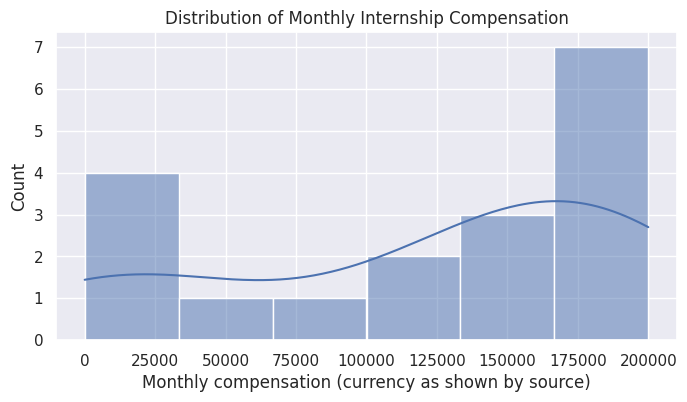

In [ ]:
if len(stipends):
    plt.figure(figsize=(8, 4))
    sns.histplot(stipends, kde=True)
    plt.title("Distribution of Monthly Internship Compensation")
    plt.xlabel("Monthly compensation (currency as shown by source)")
    plt.show()
else:
    print("No stipend values to plot.")

### Task B2: Box plot for monthly stipend

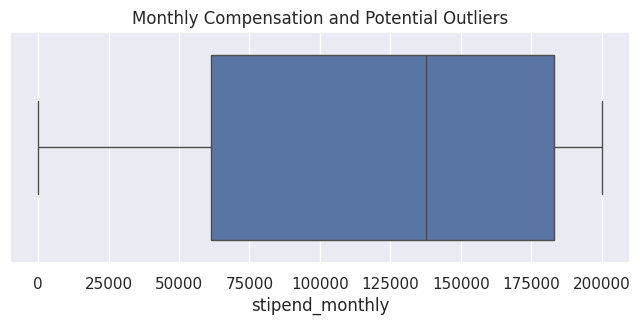

In [ ]:
if len(stipends):
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=stipends)
    plt.title("Monthly Compensation and Potential Outliers")
    plt.show()

### Task B3: Number of listings by location

In [ ]:
if len(df):
    display(df["location"].replace("", "Not specified").value_counts().head(15))

,count
location,
Not specified,51


### Task B4: Remote versus non-remote listings

In [ ]:
if len(df):
    display(df["is_remote"].value_counts().rename(index={0:"Not marked remote", 1:"Remote/WFH"}))

,count
is_remote,
Remote/WFH,50
Not marked remote,1


### Task B5: Average stipend by remote status

In [ ]:
if "stipend_monthly" in df and df["stipend_monthly"].notna().any():
    display(df.groupby("is_remote")["stipend_monthly"].agg(["count", "mean", "median"]).rename(index={0:"Not marked remote",1:"Remote/WFH"}))

,count,mean,median
is_remote,,,
Not marked remote,0,NaN,NaN
Remote/WFH,18,120974.444444,137500.0


### Task B6: Top job titles

In [ ]:
if len(df):
    display(df["title"].replace("", "Not specified").value_counts().head(15))

,count
title,
Recruiter,2
Find what's next,1
Managing Video Editor,1
AI Engineer - NY,1
Office Administrator,1
Director of Revenue Operations,1
Senior Engineer,1
Senior Software Engineer (AI Agents),1
"Software Engineer, Financial Systems",1


### Task B7: Scatter plot of description length versus stipend

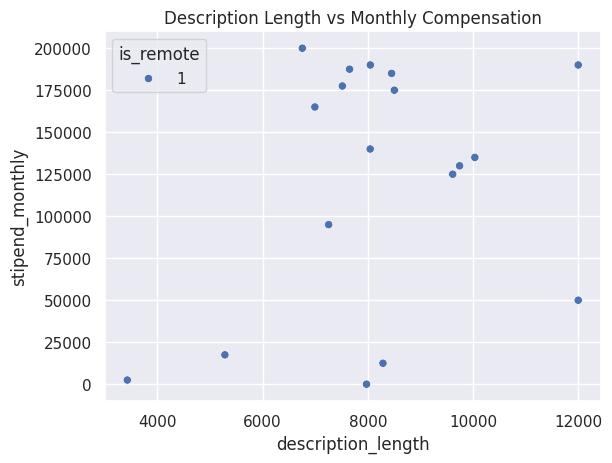

In [ ]:
plot_df = df.dropna(subset=["stipend_monthly"])
if len(plot_df):
    sns.scatterplot(data=plot_df, x="description_length", y="stipend_monthly", hue="is_remote")
    plt.title("Description Length vs Monthly Compensation")
    plt.show()

### Task B8: Correlation heatmap

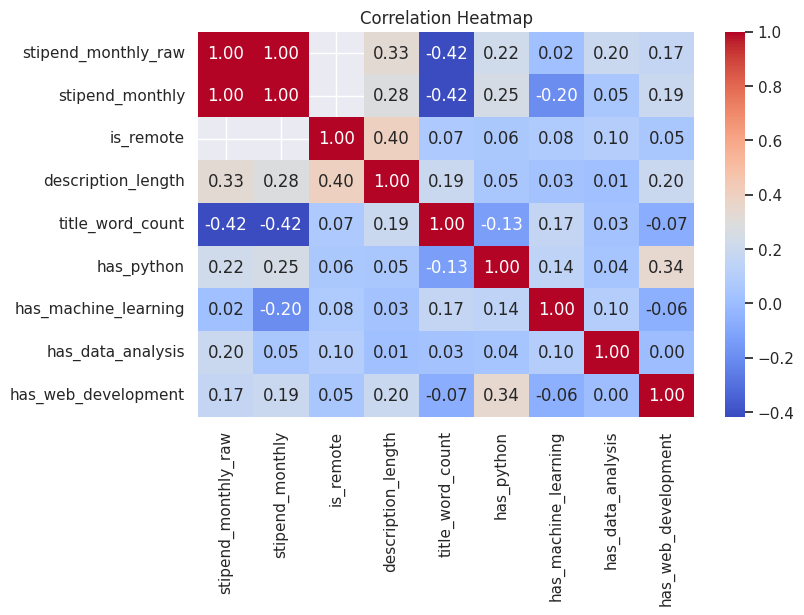

In [ ]:
if len(numeric_df.columns) > 1:
    plt.figure(figsize=(8, 5))
    sns.heatmap(numeric_df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.show()

## Practical 4: Central Limit Theorem and Point Estimation

The scraped listings are an observed sample, not the full population of all internships. These exercises demonstrate sampling behavior on the available monthly-compensation values.

### Task 1: Define the observed population and sample statistics

In [ ]:
population = pd.to_numeric(df["stipend_monthly"], errors="coerce").dropna().to_numpy()
if len(population):
    print("Valid compensation records:", len(population))
    print("Observed mean:", population.mean())
    print("Observed standard deviation:", population.std(ddof=1) if len(population) > 1 else np.nan)
else:
    print("No valid compensation values available for CLT.")

Valid compensation records: 18
Observed mean: 120974.44444444444
Observed standard deviation: 72701.87304183331


### Task 2: Visualize the stipend distribution

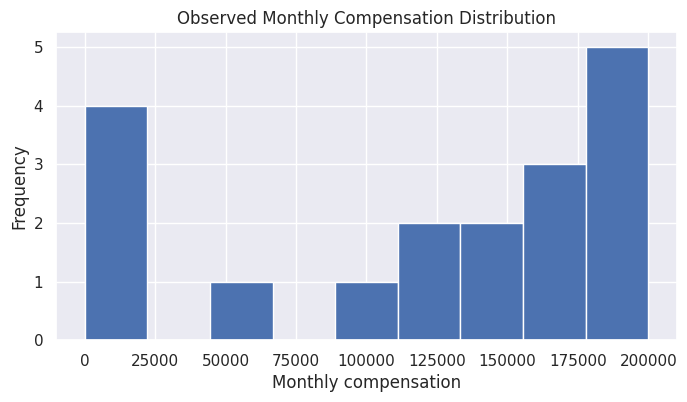

In [ ]:
if len(population):
    plt.figure(figsize=(8, 4))
    plt.hist(population, bins=min(20, max(5, len(population)//2)))
    plt.title("Observed Monthly Compensation Distribution")
    plt.xlabel("Monthly compensation")
    plt.ylabel("Frequency")
    plt.show()

### Task 3: Repeated sampling and sample means

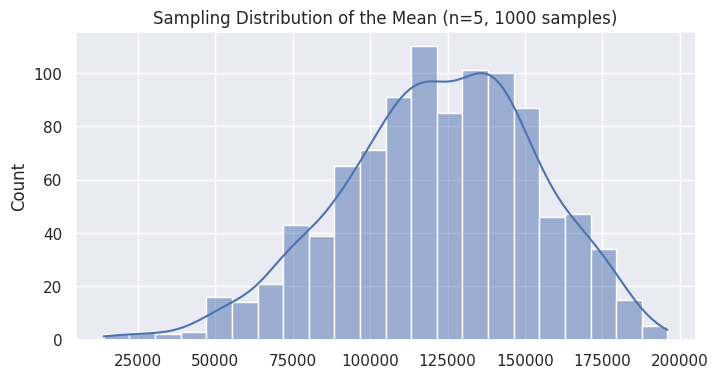

In [ ]:
if len(population) >= 2:
    rng = np.random.default_rng(42)
    n = min(5, len(population))
    sample_means = [rng.choice(population, size=n, replace=True).mean() for _ in range(1000)]
    plt.figure(figsize=(8, 4))
    sns.histplot(sample_means, kde=True)
    plt.title(f"Sampling Distribution of the Mean (n={n}, 1000 samples)")
    plt.show()
else:
    print("At least two records are needed.")

### Task 4: Compare sample means for different sample sizes

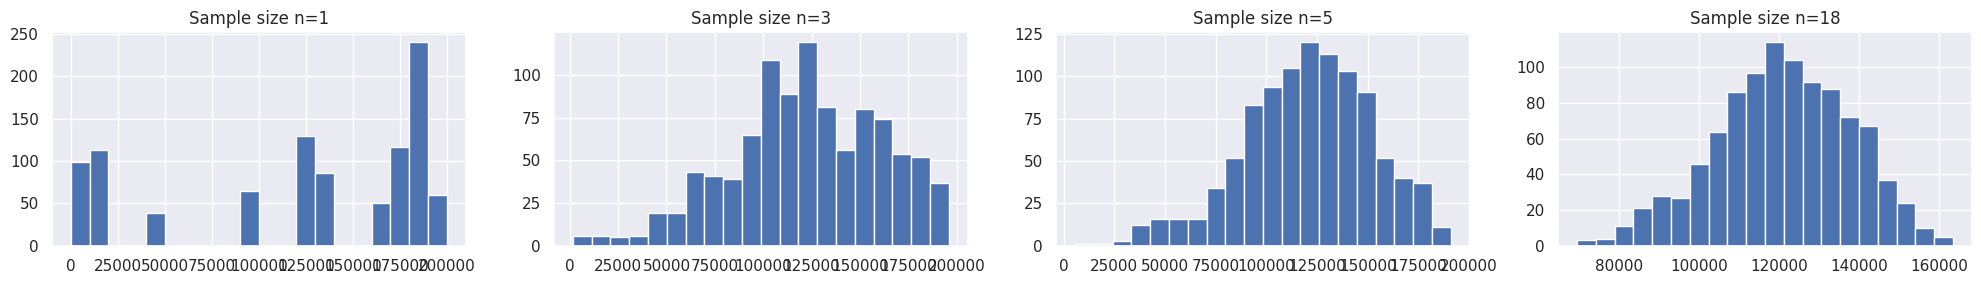

In [ ]:
if len(population) >= 2:
    rng = np.random.default_rng(42)
    sizes = sorted(set([1, min(3, len(population)), min(5, len(population)), len(population)]))
    clt_results = {}
    for n in sizes:
        clt_results[n] = [rng.choice(population, size=n, replace=True).mean() for _ in range(1000)]
    fig, axes = plt.subplots(1, len(clt_results), figsize=(5*len(clt_results), 3))
    if len(clt_results) == 1:
        axes = [axes]
    for ax, (n, values) in zip(axes, clt_results.items()):
        ax.hist(values, bins=20)
        ax.set_title(f"Sample size n={n}")
    plt.tight_layout()
    plt.show()

### Task 5: Compare empirical and theoretical standard error

In [ ]:
if len(population) > 1:
    n = min(5, len(population))
    empirical_se = np.std(clt_results[n], ddof=1) if "clt_results" in globals() and n in clt_results else np.nan
    theoretical_se = np.std(population, ddof=1) / np.sqrt(n)
    print("Empirical SD of sample means:", empirical_se)
    print("Theoretical standard error:", theoretical_se)

Empirical SD of sample means: 31758.688879645048
Theoretical standard error: 32513.26604261974


### Task 6: Point estimation of mean and variance

In [ ]:
if len(population) >= 2:
    rng = np.random.default_rng(21)
    sample = rng.choice(population, size=max(2, int(0.7*len(population))), replace=True)
    print("Sample mean estimate:", sample.mean())
    print("Sample variance estimate:", sample.var(ddof=1))
    print("Observed-data mean:", population.mean())
    print("Observed-data variance:", population.var(ddof=1))

Sample mean estimate: 99170.0
Sample variance estimate: 7607612254.545455
Observed-data mean: 120974.44444444444
Observed-data variance: 5285562343.790851


### Task 7: 95% confidence interval for the mean

In [ ]:
if len(population) >= 2:
    n = len(population)
    mean_value = np.mean(population)
    sem = stats.sem(population)
    lower, upper = stats.t.interval(0.95, df=n-1, loc=mean_value, scale=sem)
    print(f"95% t-confidence interval: ({lower:.2f}, {upper:.2f})")
else:
    print("At least two numeric values are required.")

95% t-confidence interval: (84820.65, 157128.24)


### Task 8: Effect of sample size on point estimate accuracy

In [ ]:
if len(population) >= 2:
    rng = np.random.default_rng(42)
    true_observed_mean = population.mean()
    rows = []
    for n in sorted(set([2, min(5, len(population)), min(10, len(population)), len(population)])):
        estimates = [rng.choice(population, size=n, replace=True).mean() for _ in range(500)]
        rows.append({"sample_size": n, "mean_estimate": np.mean(estimates),
                     "estimate_sd": np.std(estimates, ddof=1),
                     "absolute_error_from_observed_mean": abs(np.mean(estimates)-true_observed_mean)})
    display(pd.DataFrame(rows))

,sample_size,mean_estimate,estimate_sd,absolute_error_from_observed_mean
0,2,124462.000000,49005.150296,3487.555556
1,5,121926.824000,30552.894210,952.379556
2,10,120329.732000,24096.084236,644.712444
3,18,120941.917778,16942.176092,32.526667


## Practical 5: Hypothesis Testing

Example question: is the average monthly compensation in the scraped sample different from a chosen reference value? Set the reference value to an amount that is justified by your project question. The default below is only an example, not an official benchmark.

In [ ]:
REFERENCE_STIPEND = 10000
if len(population) >= 2:
    t_stat, p_value = stats.ttest_1samp(population, popmean=REFERENCE_STIPEND)
    print("H0: Population mean equals reference stipend")
    print("H1: Population mean differs from reference stipend")
    print("Reference value:", REFERENCE_STIPEND)
    print("t statistic:", t_stat)
    print("p-value:", p_value)
    print("Decision at 5%:", "Reject H0" if p_value < 0.05 else "Fail to reject H0")
else:
    print("At least two numeric compensation values are required.")

H0: Population mean equals reference stipend
H1: Population mean differs from reference stipend
Reference value: 10000
t statistic: 6.4761012822811574
p-value: 5.697697410045665e-06
Decision at 5%: Reject H0


### Correlation hypothesis test

In [ ]:
if len(df.dropna(subset=["stipend_monthly"])) >= 3 and df["description_length"].nunique() > 1:
    corr_df = df[["stipend_monthly", "description_length"]].dropna()
    r, p = stats.pearsonr(corr_df["description_length"], corr_df["stipend_monthly"])
    print("Pearson correlation:", r)
    print("p-value:", p)
else:
    print("Not enough valid data or variation for correlation testing.")

Pearson correlation: 0.2819931671880591
p-value: 0.2569187447421203


## Practical 6: Regression Models – Stipend Prediction

The target is `stipend_monthly`. Because scraped job listings are often sparse, results are only meaningful when enough records contain reliable numeric monthly compensation. Inspect a few records manually before interpreting model scores.

The model uses title, company, location, remote status, description length, and keyword indicators. Features derived from listing text can help describe roles, but they may not fully explain compensation.

In [ ]:
model_df = df.copy()
model_df["stipend_monthly"] = pd.to_numeric(model_df["stipend_monthly"], errors="coerce")
model_df = model_df.dropna(subset=["stipend_monthly"])
model_df = model_df[model_df["stipend_monthly"] >= 0].copy()

feature_columns = [
    "title", "company", "location", "is_remote", "description_length",
    "title_word_count", "has_python", "has_machine_learning",
    "has_data_analysis", "has_web_development"
]
for col in feature_columns:
    if col not in model_df.columns:
        model_df[col] = 0 if col not in ["title", "company", "location"] else ""

X = model_df[feature_columns]
y = model_df["stipend_monthly"]

print("Rows available for modelling:", len(model_df))
print("Feature columns:", feature_columns)

Rows available for modelling: 18
Feature columns: ['title', 'company', 'location', 'is_remote', 'description_length', 'title_word_count', 'has_python', 'has_machine_learning', 'has_data_analysis', 'has_web_development']


### Train-test split and preprocessing

In [ ]:
if len(model_df) >= 10 and y.nunique() >= 2:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    categorical_features = ["title", "company", "location"]
    numeric_features = [c for c in feature_columns if c not in categorical_features]

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessor = ColumnTransformer([
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])
    print("Training rows:", len(X_train), "Testing rows:", len(X_test))
else:
    print("Need at least 10 valid records and at least two distinct target values. Collect more permitted public listings before modelling.")

Training rows: 14 Testing rows: 4


### Train and compare all five required regression models

In [ ]:
if len(model_df) >= 10 and y.nunique() >= 2:
    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(random_state=42),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
        "KNN": KNeighborsRegressor(n_neighbors=min(5, max(1, len(X_train)-1))),
        "SVR": SVR()
    }

    results = []
    fitted_models = {}
    for name, estimator in models.items():
        pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        results.append({
            "Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "MSE": mean_squared_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred) if len(y_test) > 1 else np.nan
        })
        fitted_models[name] = pipe

    results_df = pd.DataFrame(results).sort_values("RMSE")
    display(results_df)
else:
    print("Modelling skipped because the dataset does not meet the minimum size/target variation checks.")

,Model,MAE,MSE,RMSE,R2
4,SVR,64375.112653,5.398458e+09,73474.197844,-0.074738
3,KNN,68000.000000,5.857375e+09,76533.489402,-0.166100
1,Decision Tree,73125.000000,6.082812e+09,77992.387449,-0.210981
0,Linear Regression,68608.859837,6.473327e+09,80456.986853,-0.288725
2,Random Forest,70437.500000,8.842469e+09,94034.403611,-0.760380


### Visual comparison of model performance

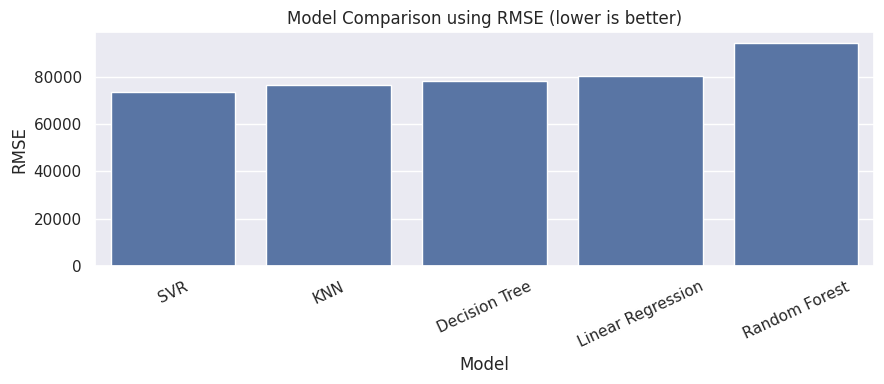

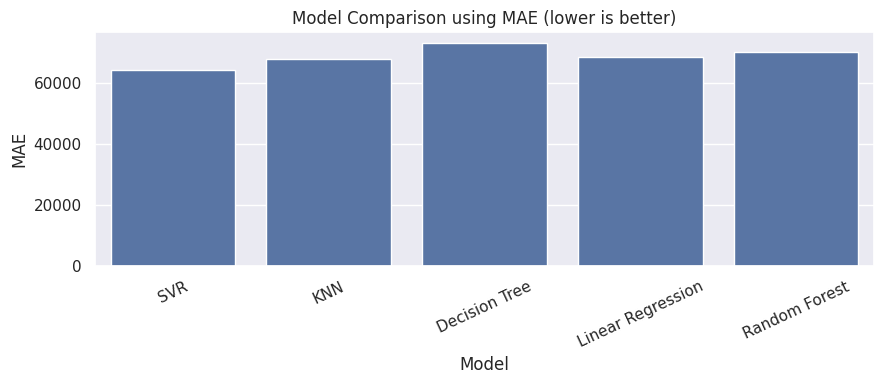

In [ ]:
if "results_df" in globals() and not results_df.empty:
    plt.figure(figsize=(9, 4))
    sns.barplot(data=results_df, x="Model", y="RMSE")
    plt.title("Model Comparison using RMSE (lower is better)")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 4))
    sns.barplot(data=results_df, x="Model", y="MAE")
    plt.title("Model Comparison using MAE (lower is better)")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

### Actual versus predicted values for the best model

Best model by RMSE: SVR


,Actual monthly compensation,Predicted monthly compensation
0,175000.0,137500.352299
1,190000.0,137499.671551
2,95000.0,137500.276883
3,12500.0,137500.197581


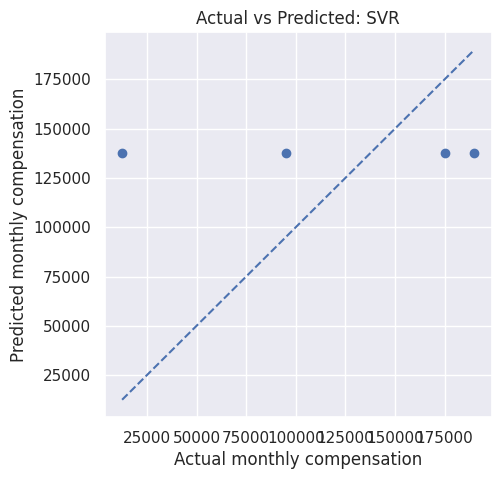

In [ ]:
if "results_df" in globals() and not results_df.empty:
    best_name = results_df.iloc[0]["Model"]
    best_model = fitted_models[best_name]
    best_predictions = best_model.predict(X_test)
    comparison = pd.DataFrame({
        "Actual monthly compensation": y_test.to_numpy(),
        "Predicted monthly compensation": best_predictions
    })
    print("Best model by RMSE:", best_name)
    display(comparison.head(15))
    plt.figure(figsize=(5, 5))
    plt.scatter(y_test, best_predictions)
    low = min(y_test.min(), best_predictions.min())
    high = max(y_test.max(), best_predictions.max())
    plt.plot([low, high], [low, high], linestyle="--")
    plt.xlabel("Actual monthly compensation")
    plt.ylabel("Predicted monthly compensation")
    plt.title(f"Actual vs Predicted: {best_name}")
    plt.show()

### Predict stipend for a new listing

In [ ]:
if "fitted_models" in globals() and "best_name" in globals():
    new_listing = pd.DataFrame([{
        "title": "Data Science Intern",
        "company": "Example Company",
        "location": "Remote",
        "is_remote": 1,
        "description_length": 1200,
        "title_word_count": 3,
        "has_python": 1,
        "has_machine_learning": 1,
        "has_data_analysis": 1,
        "has_web_development": 0
    }])[feature_columns]
    predicted = fitted_models[best_name].predict(new_listing)[0]
    print(f"Estimated monthly compensation from the trained model: {predicted:,.2f}")
    print("This is a model estimate, not a guaranteed stipend or salary.")
else:
    print("Train a model successfully before trying a new prediction.")

Estimated monthly compensation from the trained model: 137,499.34
This is a model estimate, not a guaranteed stipend or salary.


## Conclusion

- Web scraping was used to collect publicly visible listing details, subject to website access rules.
- Data cleaning and exploratory data analysis were performed on the collected records.
- Sampling distributions, point estimates, confidence intervals, and hypothesis testing were demonstrated using the available numeric compensation values.
- Linear Regression, Decision Tree, Random Forest, KNN, and SVR were compared using MAE, MSE, RMSE, and R².
- The best model should be selected based on test-set performance, but a small or biased scraped sample cannot represent the whole internship market.

## Limitations
1. Some listings omit compensation or display annual salary, equity, or a range that may be difficult to parse.
2. Website HTML can change; the scraper may require selector updates.
3. Listings are not a random sample of all internships.
4. Currency and compensation periods must be verified manually before final reporting.
5. Respect the website's terms, robots directives, rate limits, and applicable law. Do not bypass technical restrictions.

In [ ]:
import streamlit as st
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Page Configuration
st.set_page_config(page_title="Internship Stipend Predictor", page_icon="💼", layout="wide")
sns.set_theme()

st.title("💼 Internship Stipend Prediction Platform")
st.write("**Student:** Dhananjay Gandhi | **Section:** B2")

# -----------------------------------------------------------------------------
# 1. DATA LOADING & SYNTHETIC FEATURE AUGMENTATION
# -----------------------------------------------------------------------------
@st.cache_data
def load_and_prepare_data():
    try:
        data = pd.read_csv("wellfound_internship_scraped_raw.csv")
    except Exception:
        rng = np.random.default_rng(42)
        mock_records = []
        titles = ["Data Science Intern", "Software Engineer", "Machine Learning Intern", "Web Developer"]
        locations = ["San Francisco", "Remote", "Bengaluru", "New York"]
        for i in range(100):
            stip = float(rng.choice([20000, 35000, 50000, 80000, 120000, 150000])) if i % 5 != 0 else np.nan
            mock_records.append({
                "title": rng.choice(titles),
                "company": f"Startup {i}",
                "location": rng.choice(locations),
                "stipend_monthly": stip,
                "description_text": "Sample description text with python, machine learning, and data analysis."
            })
        data = pd.DataFrame(mock_records)

    # Standard cleanups
    for col in ["title", "company", "location", "description_text"]:
        if col not in data.columns:
            data[col] = ""
        data[col] = data[col].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

    data["description_lower"] = data["description_text"].str.lower()

    if "is_remote" not in data.columns or data["is_remote"].isnull().all():
        data["is_remote"] = data.apply(
            lambda r: int(any(k in (str(r["location"]) + " " + str(r["description_lower"])).lower()
                              for k in ["remote", "work from home", "wfh"])), axis=1
        )

    # Extract text skills
    data["has_python"] = data["description_lower"].str.contains(r"\bpython\b", regex=True).astype(int)
    data["has_machine_learning"] = data["description_lower"].str.contains(r"machine learning|\bml\b", regex=True).astype(int)
    data["has_data_analysis"] = data["description_lower"].str.contains(r"data analysis|analytics", regex=True).astype(int)
    data["has_web_development"] = data["description_lower"].str.contains(r"web development|frontend|backend", regex=True).astype(int)

    # Generate realistic student metrics (Projects, Certificates, CGPA) if not present
    rng = np.random.default_rng(42)
    if "num_projects" not in data.columns:
        data["num_projects"] = rng.integers(1, 10, size=len(data))
    if "num_certificates" not in data.columns:
        data["num_certificates"] = rng.integers(0, 6, size=len(data))
    if "cgpa" not in data.columns:
        data["cgpa"] = np.round(rng.uniform(6.5, 9.8, size=len(data)), 2)

    return data

df = load_and_prepare_data()

# -----------------------------------------------------------------------------
# 2. INTERFACE TABS
# -----------------------------------------------------------------------------
tab1, tab2, tab3, tab4, tab5 = st.tabs([
    "📊 EDA",
    "🎲 Central Limit Theorem",
    "🔬 Hypothesis Testing",
    "🤖 ML Model Training",
    "🔮 Predict My Stipend"
])

# --- TAB 1: EDA ---
with tab1:
    st.header("Exploratory Data Analysis")
    st.write(f"Total dataset records: **{len(df)}**")

    # Using st.table instead of st.dataframe to fix Localtunnel dynamic module fetch errors
    st.subheader("Data Sample Preview")
    st.table(df[["title", "company", "location", "stipend_monthly", "num_projects", "num_certificates", "cgpa"]].head(8))

    c1, c2 = st.columns(2)
    with c1:
        st.subheader("Stipend Distribution")
        fig, ax = plt.subplots(figsize=(6, 3.5))
        valid_stipends = df["stipend_monthly"].dropna()
        if len(valid_stipends) > 0:
            sns.histplot(valid_stipends, kde=True, ax=ax, color="skyblue")
            st.pyplot(fig)
        else:
            st.warning("No numeric stipend values available.")

    with c2:
        st.subheader("Stipend vs Number of Projects")
        fig, ax = plt.subplots(figsize=(6, 3.5))
        sns.scatterplot(data=df.dropna(subset=["stipend_monthly"]), x="num_projects", y="stipend_monthly", hue="is_remote", ax=ax)
        st.pyplot(fig)

# --- TAB 2: CLT DEMO ---
with tab2:
    st.header("Central Limit Theorem Demonstration")
    population = df["stipend_monthly"].dropna().values
    if len(population) >= 5:
        n_val = st.slider("Sample Size (n)", 2, len(population), min(10, len(population)))
        sample_means = [np.random.choice(population, size=n_val, replace=True).mean() for _ in range(1000)]

        fig, ax = plt.subplots(figsize=(8, 3.5))
        sns.histplot(sample_means, kde=True, ax=ax, color="purple")
        st.pyplot(fig)

        c_e1, c_e2 = st.columns(2)
        c_e1.metric("Empirical Standard Error", f"{np.std(sample_means):.2f}")
        c_e2.metric("Theoretical Standard Error", f"{(np.std(population, ddof=1)/np.sqrt(n_val)):.2f}")
    else:
        st.info("Insufficient data for CLT simulation.")

# --- TAB 3: HYPOTHESIS TESTING ---
with tab3:
    st.header("Hypothesis Testing")
    ref_stipend = st.number_input("Benchmark Stipend for 1-Sample t-test", value=40000)
    if len(population) >= 5:
        t_stat, p_value = stats.ttest_1samp(population, popmean=ref_stipend)
        c1, c2, c3 = st.columns(3)
        c1.metric("t-Statistic", f"{t_stat:.4f}")
        c2.metric("p-Value", f"{p_value:.4f}")
        c3.metric("Reject Null (α=0.05)?", "YES" if p_value < 0.05 else "NO")
    else:
        st.info("Insufficient data for t-test.")

# --- TAB 4: ML MODEL TRAINING ---
with tab4:
    st.header("ML Model Training & Evaluation")
    model_df = df.dropna(subset=["stipend_monthly"]).copy()

    if len(model_df) >= 5:
        feature_cols = [
            "title", "company", "location", "is_remote",
            "num_projects", "num_certificates", "cgpa",
            "has_python", "has_machine_learning", "has_data_analysis", "has_web_development"
        ]
        X = model_df[feature_cols]
        y = model_df["stipend_monthly"]

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

        cat_cols = ["title", "company", "location"]
        num_cols = [c for c in feature_cols if c not in cat_cols]

        preprocessor = ColumnTransformer([
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
            ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
        ])

        models = {
            "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
            "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
        }

        results = []
        trained_pipelines = {}

        for name, model in models.items():
            pipe = Pipeline([("prep", preprocessor), ("algo", model)])
            pipe.fit(X_train, y_train)
            preds = pipe.predict(X_test)

            rmse = np.sqrt(mean_squared_error(y_test, preds))
            mae = mean_absolute_error(y_test, preds)
            results.append({"Model": name, "RMSE": round(rmse, 2), "MAE": round(mae, 2)})
            trained_pipelines[name] = pipe

        res_df = pd.DataFrame(results).sort_values("RMSE")
        st.table(res_df)

        best_name = res_df.iloc[0]["Model"]
        st.session_state["predictor_pipeline"] = trained_pipelines[best_name]
        st.success(f"Top model **{best_name}** trained successfully and ready for prediction!")
    else:
        st.error("Not enough valid data to train models.")

# --- TAB 5: PREDICT MY STIPEND (FULLY INTERACTIVE) ---
with tab5:
    st.header("🔮 Interactive Stipend Calculator")
    st.write("Apni profile ke details daalo aur live predict karo ki kitna stipend milega!")

    if "predictor_pipeline" in st.session_state:
        col_a, col_b = st.columns(2)

        with col_a:
            st.subheader("👨‍🎓 Your Student Profile")
            user_projects = st.slider("Number of Completed Projects", min_value=0, max_value=15, value=4)
            user_certs = st.slider("Number of Certifications", min_value=0, max_value=10, value=2)
            user_cgpa = st.slider("CGPA / Score", min_value=5.0, max_value=10.0, value=8.2, step=0.1)

            st.write("**Skills You Possess:**")
            u_py = st.checkbox("Python Programming", value=True)
            u_ml = st.checkbox("Machine Learning / AI", value=True)
            u_da = st.checkbox("Data Analysis / SQL", value=False)
            u_web = st.checkbox("Web Development", value=False)

        with col_b:
            st.subheader("🎯 Target Job Details")
            titles_list = list(df["title"].unique()) if len(df["title"].unique()) > 0 else ["Data Science Intern"]
            companies_list = list(df["company"].unique()) if len(df["company"].unique()) > 0 else ["Startup"]
            locations_list = list(df["location"].unique()) if len(df["location"].unique()) > 0 else ["Remote"]

            u_title = st.selectbox("Desired Job Title", titles_list)
            u_company = st.selectbox("Target Company", companies_list)
            u_location = st.selectbox("Location", locations_list)
            u_remote = st.radio("Work Mode", options=[1, 0], format_func=lambda x: "Remote" if x == 1 else "On-Site")

        # Prepare Payload DataFrame
        input_data = pd.DataFrame([{
            "title": u_title,
            "company": u_company,
            "location": u_location,
            "is_remote": u_remote,
            "num_projects": user_projects,
            "num_certificates": user_certs,
            "cgpa": user_cgpa,
            "has_python": int(u_py),
            "has_machine_learning": int(u_ml),
            "has_data_analysis": int(u_da),
            "has_web_development": int(u_web)
        }])

        # Live Inference
        predicted_stipend = st.session_state["predictor_pipeline"].predict(input_data)[0]
        final_val = max(0, predicted_stipend)

        st.markdown("---")

        m1, m2 = st.columns(2)
        m1.metric("Predicted Monthly Stipend", f"₹ {final_val:,.2f}")

        dataset_avg = df["stipend_monthly"].mean()
        m2.metric("Average Dataset Stipend", f"₹ {dataset_avg:,.2f}", delta=f"₹ {final_val - dataset_avg:,.2f}")

    else:
        st.warning("Pehle **🤖 ML Model Training** tab me jao taaki model train ho sake!")

2026-10-27 05:12:53.301 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 05:12:53.305 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 05:12:53.310 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 05:12:53.314 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 05:12:53.317 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 05:12:53.323 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 05:12:53.329 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 05:12:53.335 No runtime found, using MemoryCacheStorageManager
2026-10-27 05:12:53.343 No runtime found, us

In [ ]:
# 1. Clean app.py by removing the invalid trailing shell commands
with open('app.py', 'r') as f:
    lines = f.readlines()

clean_lines = []
for line in lines:
    if line.strip().startswith('!') or 'npx localtunnel' in line or 'streamlit run' in line:
        # Skip shell command lines
        continue
    clean_lines.append(line)

with open('app.py', 'w') as f:
    f.writelines(clean_lines)

print("Cleaned app.py successfully! Starting Streamlit server...")

# 2. Re-install packages if needed and start the tunnel securely
!pip install -q streamlit
!npm install -g localtunnel
!streamlit run app.py & npx localtunnel --port 8501

Cleaned app.py successfully! Starting Streamlit server...
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
changed 22 packages in 2s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇⠙⠹

⠸⠼⠴⠦your url is: https://old-peaches-wonder.loca.lt
2026-10-27 05:13:10.692 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.80.98.24:8501

